# The pipeline with an affordance map, one step at a time: what goes in, what comes out
**VLA direction** · LIBERO-Object · released starVLA checkpoint with the plan input of 11 Nov 2026 · a walk-through for discussion, not a result

- **What this is:** one closed-loop rollout, stopped at one moment. That moment is followed through the nine steps of the pipeline, with the input and the output of every step drawn or printed. The last part shows the whole episode.
- **Real:** the images, the depth image and the camera, the VLM and the action head, the plan input sent with each query, the action chunks, the motion of the robot.
- **ORACLE:** the affordance map, the planned contact, the approach direction, the kind of event, and the episode state. They are computed from the simulator. No model predicts them yet.
- **How the rollout was driven:** by the ORACLE contact (object position plus the average grasp point of the demonstrations). The affordance map is drawn next to it; it did not steer the robot.

| step | input | output | in this notebook |
| --- | --- | --- | --- |
| 1 · observation | — | two images, depth, camera, instruction, gripper position | real |
| 2 · VLM | images, instruction | hidden states | real (sizes measured on 10 Nov) |
| 3 · affordance head | hidden states | affordance map over the image | **ORACLE** |
| 4 · contact from the map | map, depth, camera | a 3D point | geometry real, map ORACLE |
| 5 · plan head | hidden states | approach direction, grasp or release | **ORACLE** |
| 6 · plan encoding | contact relative to the gripper, approach, event | ten numbers, then one vector | real |
| 7 · action head | hidden states, plan vector | action chunk, 8 steps × 7 numbers | real |
| 8 · controller | action chunk | motion of the robot | real |
| 9 · episode state | map, depth, camera | one slot per object, fed back into step 2 | **ORACLE**, rule-based, not connected |

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance_vla").is_dir())
sys.path.insert(0, str(ROOT))
from affordance_vla.sim.rollout_log import load_rollout_log
from report import affordance_pipeline_helpers as A
from report import vla_pipeline_demo_helpers as H
from report import vla_pipeline_demo_labels as L

set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_colwidth", 140)

RUNS = ROOT / "runs" / "plan_following"
ROLLOUTS = RUNS / "s2_actions" / "rollouts_oracle_depth"   # the policy trained with moved plans, logged with depth
ROLLOUT, STEP = "ask_tomato_sauce_ep1", 24                    # the rollout and the moment that are followed
stats = json.loads((RUNS / "dataset" / "stats.json").read_text())
SCALE, CONTAINER = stats["motion_scale_m_per_unit"], stats["container"]
probe = H.load_probe(ROOT / "runs" / "vla_pipeline_demo" / "probe")  # sizes of the same frozen VLM, 10 Nov

log = load_rollout_log(ROLLOUTS / f"{ROLLOUT}.npz")
plans = A.load_plans(log)
view = A.view_at(log, plans, STEP, CONTAINER)
print(f"instruction: “{log.meta['instruction']}”   scene of the task: “{log.meta['task']}”")
print(f"{log.steps} steps, {len(log.chunk_steps)} queries; the {H.pretty(log.target)} "
      f"{'ended in the basket' if log.delivered else 'did not end in the basket'}")
print(f"followed here: step {view.step} (query {view.query}); plan in force: {A.describe(view)}")

instruction: “pick up the tomato sauce and place it in the basket”   scene of the task: “pick up the salad dressing and place it in the basket”
173 steps, 22 queries; the tomato sauce ended in the basket
followed here: step 24 (query 3); plan in force: grasp → tomato sauce


## 1 · Observation
**This step:** what the simulator hands over before a query: the two camera images the policy sees, the depth image and the camera matrices of the agent view, the instruction, and where the gripper is.

**Status:** real. The last panel uses simulator positions and is only there to read the scene; the policy never sees it. Depth and camera are not inputs of the VLM. They are needed later, to turn a place in the image into a point in space.

,value at this step,used by
input,,
instruction,“pick up the tomato sauce and place it in the basket”,VLM
"agent view, wrist view","RGB, 256 × 256; resized to 224 × 224 for the VLM",VLM
depth of the agent view,"256 × 256, metres; here 0.74–2.79 m","step 4 (map → 3D point), step 9"
camera matrices,"intrinsics 3 × 3, camera-to-world 4 × 4","step 4, step 9"
gripper position,"[-0.153, -0.104, 0.194]",step 6 (contact relative to the gripper)


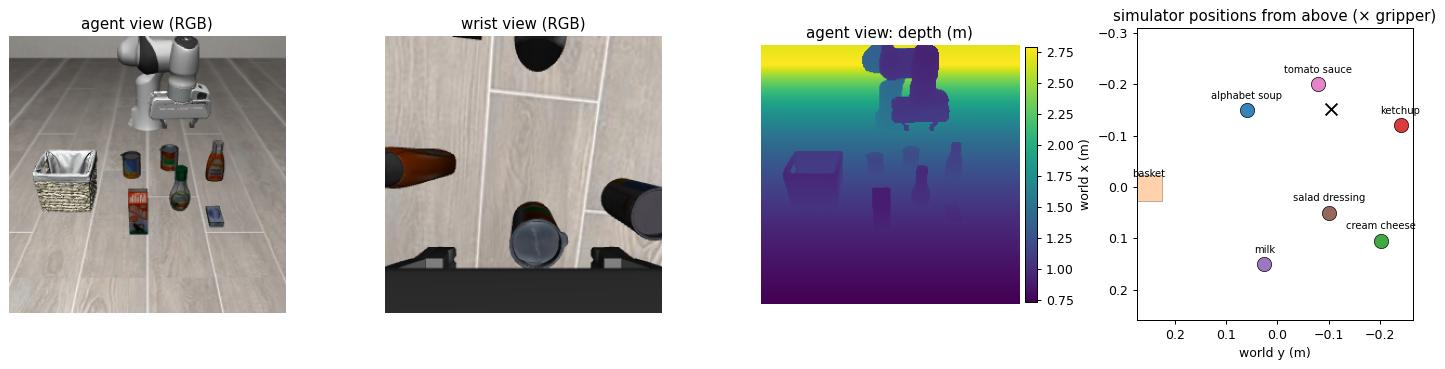

In [2]:
display(A.observation_table(log, view))
fig = A.observation_figure(log, view)
plt.show()

## 2 · VLM
**This step:** the two images and the instruction go through the vision-language model. It returns hidden states: one vector per token, at every layer. Everything downstream reads these.

**Status:** real. The sizes were measured on 10 Nov; the VLM has been frozen since, so they hold here. Each image is resized to 224 × 224 and becomes 64 tokens, drawn below as an 8 × 8 grid: a cell is the finest position the VLM's own tokens can name.

measured on 10 Nov (same frozen VLM)
    item                                                                                                                              
in  two images                                                                                    224 × 224 each → 64 tokens per image
    instruction                     “pick up the tomato sauce and place it in the basket” inside a fixed prompt → about 53 text tokens
    robot state                                                                                            not used by this checkpoint
    episode state tokens                                                                                    not connected yet (step 9)
out hidden states         36 layers × 181 tokens × 2560 numbers; the affordance head, the plan head and the action head all read these

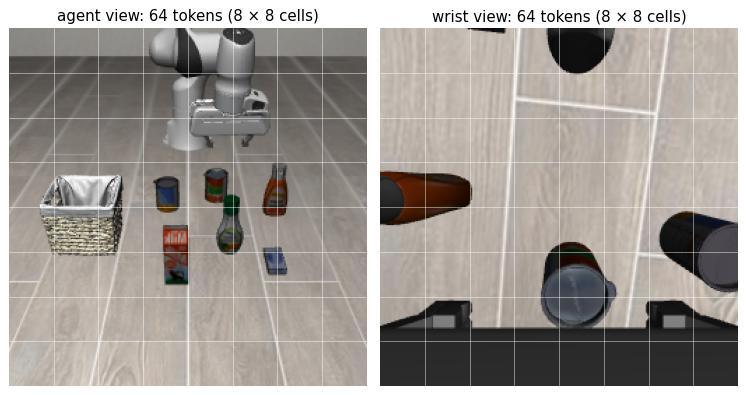

In [3]:
display(A.vlm_table(probe, log))
fig = A.token_grid_figure(log, view, probe.facts["tokens_image"] // 2)
plt.show()

## 3 · Affordance head → affordance map
**This step:** from the hidden states, mark in the image where the gripper should act on the object the instruction is about: for a grasp, the part of the object to hold; for a release, the place to put it.

**Status:** **ORACLE.** No such head exists yet. The map below is built from the simulator and is one possible definition of the label:
- take the pixels that show the object (simulator segmentation);
- lift each pixel to a 3D point with the depth image;
- a pixel scores high when its point is close to where the demonstrations hold this object (a Gaussian, 3 cm wide). For a release the distance is measured in the ground plane to the release point over the basket (4 cm wide).

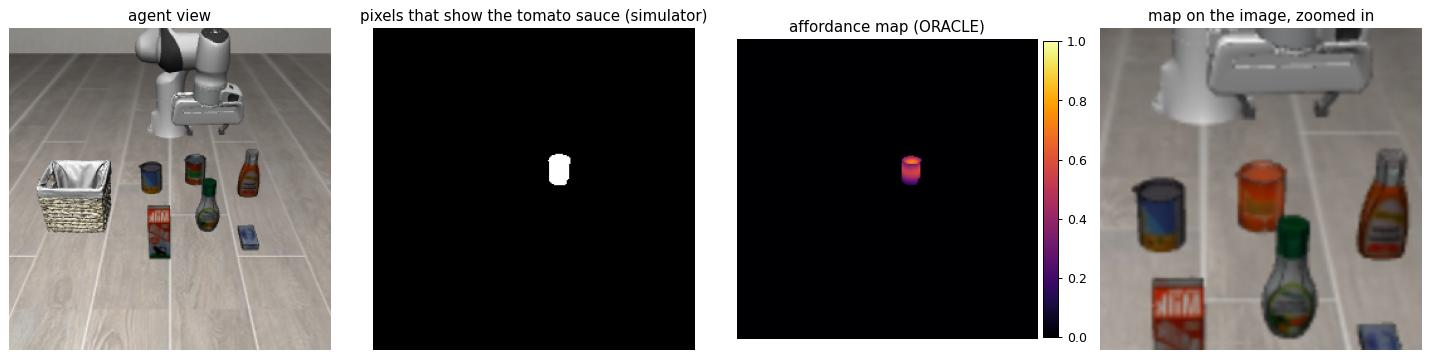

the tomato sauce shows 374 pixels, 18 wide × 25 high; one image token of the VLM covers 32 × 32 pixels of this image


In [4]:
fig = A.map_figure(log, view)
plt.show()
print(A.object_size_text(log, view, probe.facts["tokens_image"] // 2))

## 4 · From the map to a 3D point
**This step:** a map is a picture; the robot needs a point in space. Every pixel of the map is lifted to 3D with the depth image and the camera matrices, and the points are averaged with the map as weights.

**Status:** the geometry is real; the map is ORACLE. The yellow dot is the map's point. The white plus is the planned contact used in the rollout: where the gripper's centre should be at the grasp. The two differ, because a camera sees the surface of the object and the gripper's centre ends up between the fingers, inside or above it. Both are ORACLE here, so the distance between them is not the error of a model: it is how far the two definitions lie apart.

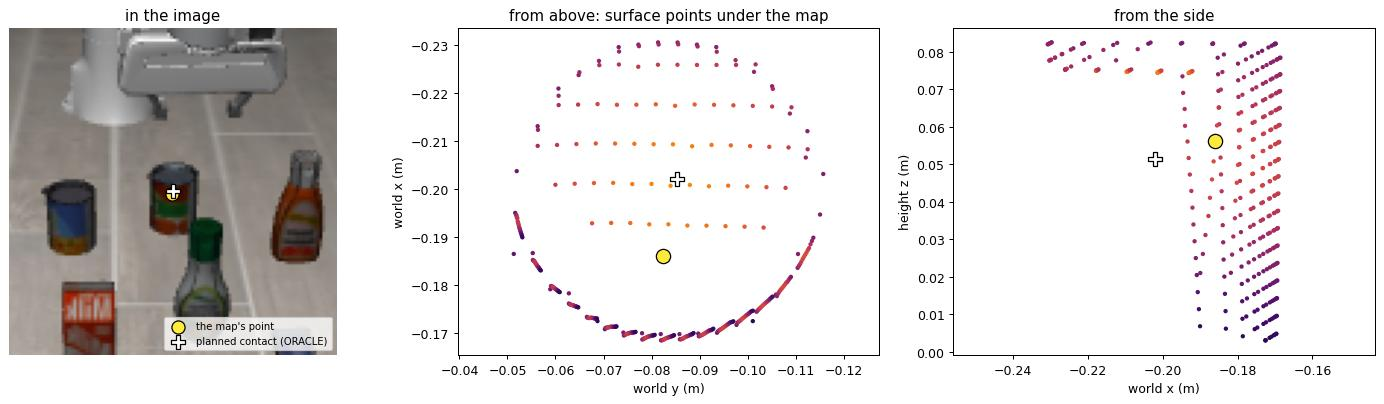

the map's point (m):       [-0.186 -0.082  0.056]
planned contact (m):       [-0.202 -0.085  0.052]
the planned contact is 1.6 cm away horizontally and -0.5 cm in height


In [5]:
fig = A.contact_figure(log, view)
plt.show()
horizontal, above = A.gap(view)
print("the map's point (m):      ", np.round(view.map_point, 3))
print("planned contact (m):      ", np.round(view.contact, 3))
print(f"the planned contact is {horizontal:.1f} cm away horizontally and {above:+.1f} cm in height")

## 5 · Plan head → approach direction and kind of event
**This step:** besides the contact, the plan says from which direction the gripper should arrive and whether the next event is a grasp or a release.

**Status:** **ORACLE.** The direction is the average direction of the demonstrations' last motion before the event, for this object. In the method these come from a plan head on the VLM.

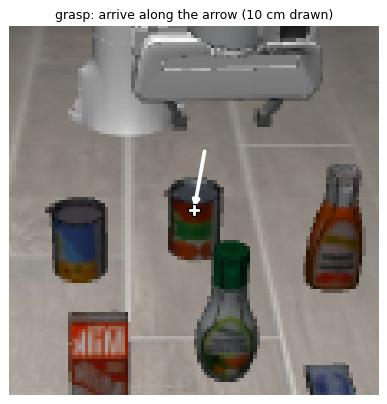

approach direction (unit vector, world): [-0.28  0.08 -0.96]   event: grasp


In [6]:
fig = A.approach_figure(log, view)
plt.show()
print("approach direction (unit vector, world):", np.round(view.approach, 2), "  event:", view.event)

## 6 · Plan encoding
**This step:** the plan becomes ten numbers: the vector from the gripper to the contact (in units of 10 cm, and again squashed so that the last centimetres count), the approach direction, and +1 for a grasp or −1 for a release. A small trained network turns them into one vector of 2,560 numbers that is added to each of the eight action tokens.

**Status:** real. The first column is what was sent in this rollout. The second column shows what the numbers would be if the contact were the map's point of step 4: the difference is the gap seen there.

In [7]:
display(A.plan_table(log, view))

,sent in this rollout (contact: ORACLE),if the contact were the map's point
to contact x / 10 cm,-0.495,-0.335
to contact y / 10 cm,0.190,0.218
to contact z / 10 cm,-1.421,-1.374
tanh(x / 2 cm),-0.986,-0.932
tanh(y / 2 cm),0.739,0.796
tanh(z / 2 cm),-1.000,-1.000
approach x,-0.284,-0.284
approach y,0.075,0.075
approach z,-0.956,-0.956
"event (+1 grasp, −1 release)",1.000,1.000


## 7 · Action head → action chunk
**This step:** the action head reads the hidden states and the plan vector and returns the next eight steps. Each step has seven numbers: how far to move the gripper in x, y and z, how much to turn it, and whether it is open (1) or closed (0).

**Status:** real; this is the output of the trained model for this query. Summing the translations and multiplying by the measured motion per unit gives the path the chunk asks for.

,dx,dy,dz,droll,dpitch,dyaw,gripper
step 24,-0.38,0.10,-0.65,-0.01,-0.00,-0.05,1.02
step 25,-0.61,-0.07,-0.70,-0.01,-0.02,-0.04,1.00
step 26,-0.15,0.10,-0.69,0.00,-0.02,-0.04,1.02
step 27,-0.30,0.29,-0.70,0.00,-0.03,-0.04,1.01
step 28,-0.34,0.34,-0.74,-0.00,-0.03,-0.02,1.03
step 29,-0.21,0.44,-0.61,-0.00,-0.02,-0.02,1.02
step 30,-0.14,0.33,-0.60,-0.00,-0.01,-0.02,1.02
step 31,-0.47,0.38,-0.58,-0.01,-0.03,-0.02,1.01


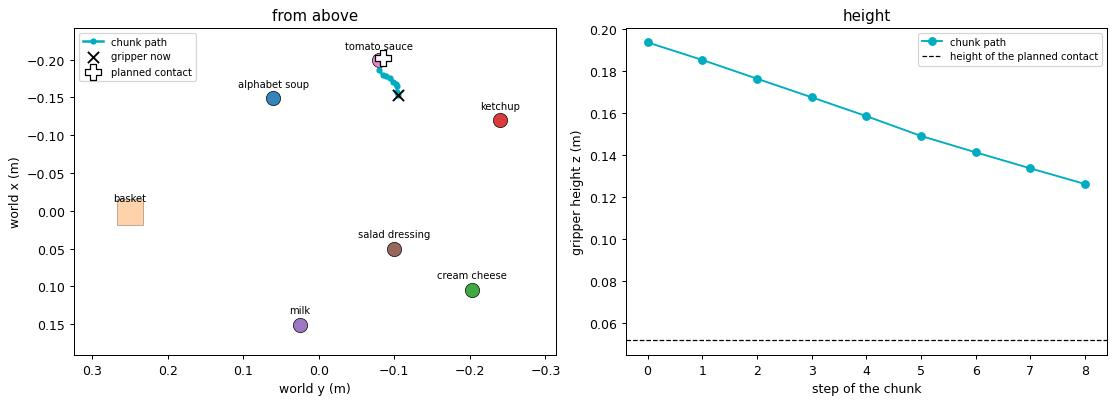

In [8]:
display(A.chunk_table(view).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.2f}"))
fig = A.chunk_figure(log, view, SCALE)
plt.show()

## 8 · Controller → motion of the robot
**This step:** the simulator's controller turns each of the eight commands into joint torques. It only follows the small step it is given; it does not plan a path and does not avoid obstacles. After the eight steps (0.4 s) the policy is queried again with a new image.

**Status:** real.

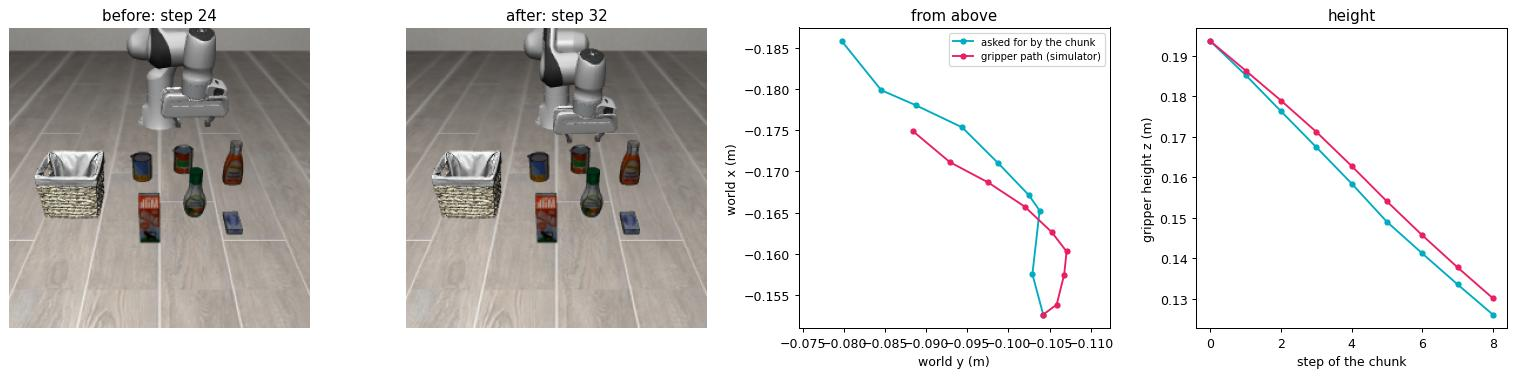

,value
gripper moved (cm),6.9
chunk asked for (cm),7.9
end of the chunk path to where the gripper ended (cm),1.5
gripper to planned contact before (cm),15.2
gripper to planned contact after (cm),8.3


In [9]:
fig = A.execution_figure(log, view, SCALE)
plt.show()
display(A.execution_table(log, view, SCALE))

## 9 · Episode state
**This step:** after the chunk, update one slot per object: where it was last seen, whether it is visible, hidden, or in the gripper, and for how long it has not been seen. In the method these slots become a few tokens for the VLM at the next query.

**Status:** **ORACLE**, rule-based, and not connected to the model. The slots are filled from simulator positions and visibility. In this scene almost nothing is ever hidden, so the state has little to do.

,status,believed position (m),steps since seen
alphabet soup,visible,"[-0.149, 0.06, 0.038]",0
basket,visible,"[0.002, 0.25, -0.005]",0
cream cheese,visible,"[0.104, -0.203, 0.009]",0
ketchup,visible,"[-0.12, -0.24, 0.072]",0
milk,visible,"[0.151, 0.025, 0.07]",0
salad dressing,visible,"[0.05, -0.1, 0.073]",0
tomato sauce,visible,"[-0.2, -0.08, 0.038]",0


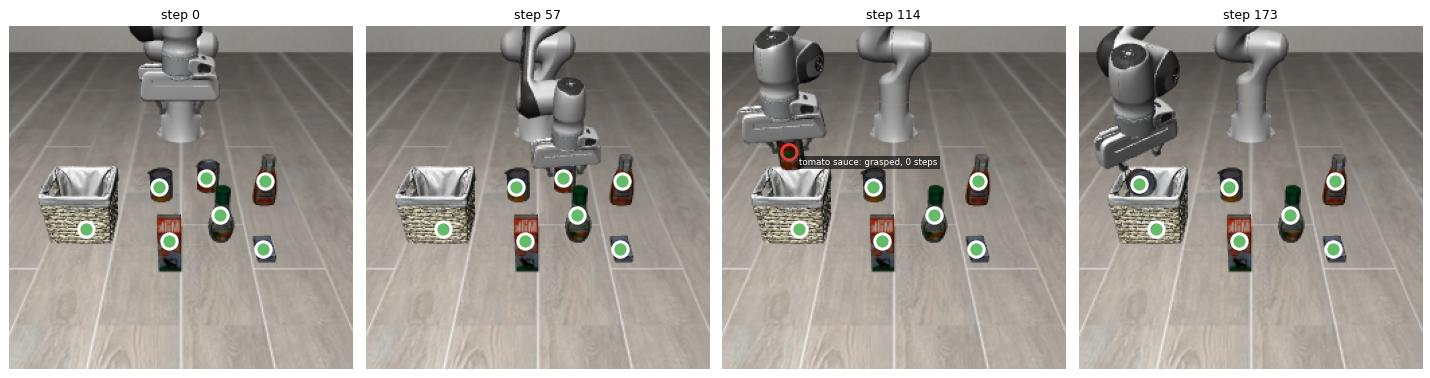

In [10]:
history = L.episode_state_history(log)
display(A.slot_table(history, min(view.query_step + 8, log.steps)))
fig = L.state_overlay_figure(log, history, L.state_key_steps(log))
plt.show()

## The whole episode
The same quantities at six queries, drawn into the agent view, then as curves over all queries, then as a video. In the video the contact stays where the latest query put it for the eight steps of a chunk, while the map follows the current image. When the object is in the gripper the plan switches to the release, and the map moves from the object to the basket. At the very last query the plan flips back to the grasp: the object has been let go but does not yet count as lying in the basket.

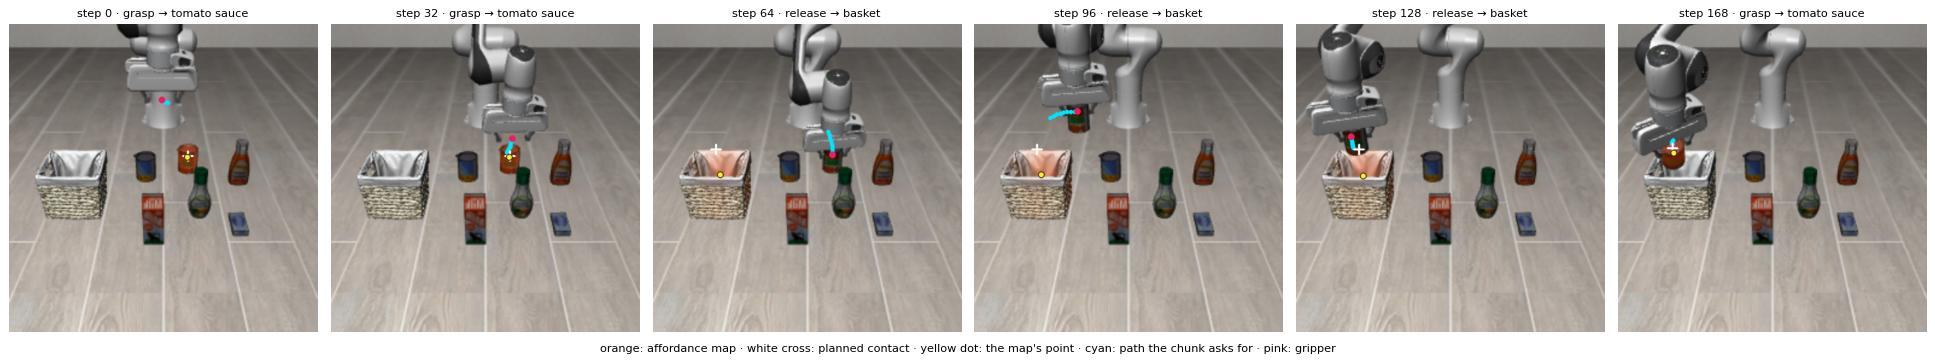

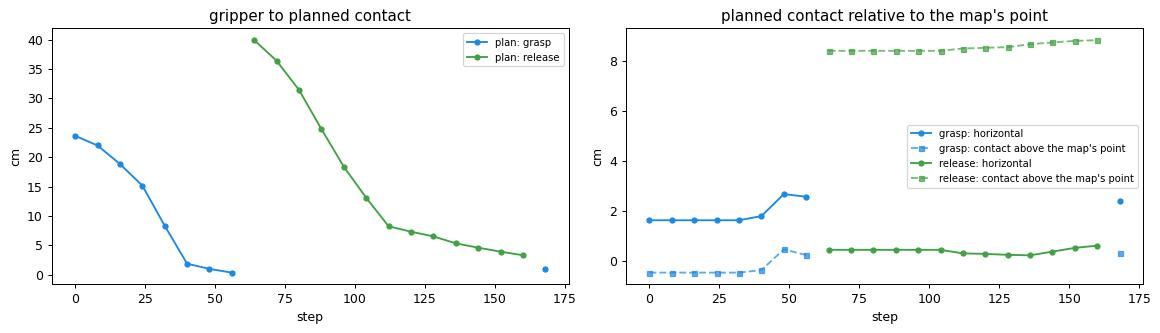

,queries,"horizontal gap, median (cm)","horizontal gap, range (cm)","contact above the map's point, median (cm)"
grasp,9,1.6,1.6–2.7,-0.5
release,13,0.4,0.2–0.6,8.5


In [11]:
views = [A.view_at(log, plans, int(step), CONTAINER) for step in log.chunk_steps]
picks = [views[k] for k in np.unique(np.linspace(0, len(views) - 1, 6).astype(int))]
fig = A.film_strip(log, picks, SCALE)
plt.show()
fig = A.timeline_figure(log, views)
plt.show()
display(A.gap_table(views))

In [12]:
CLIP = ROOT / "report" / "media" / "affordance_pipeline_walkthrough.mp4"  # tracked in git
A.render_overlay_video(log, plans, CONTAINER, SCALE, CLIP)
Video(str(CLIP), embed=True, width=560)

**Another condition, same policy:** the task's own instruction, with the salad dressing moved 9 cm from its place. The map follows the bottle.

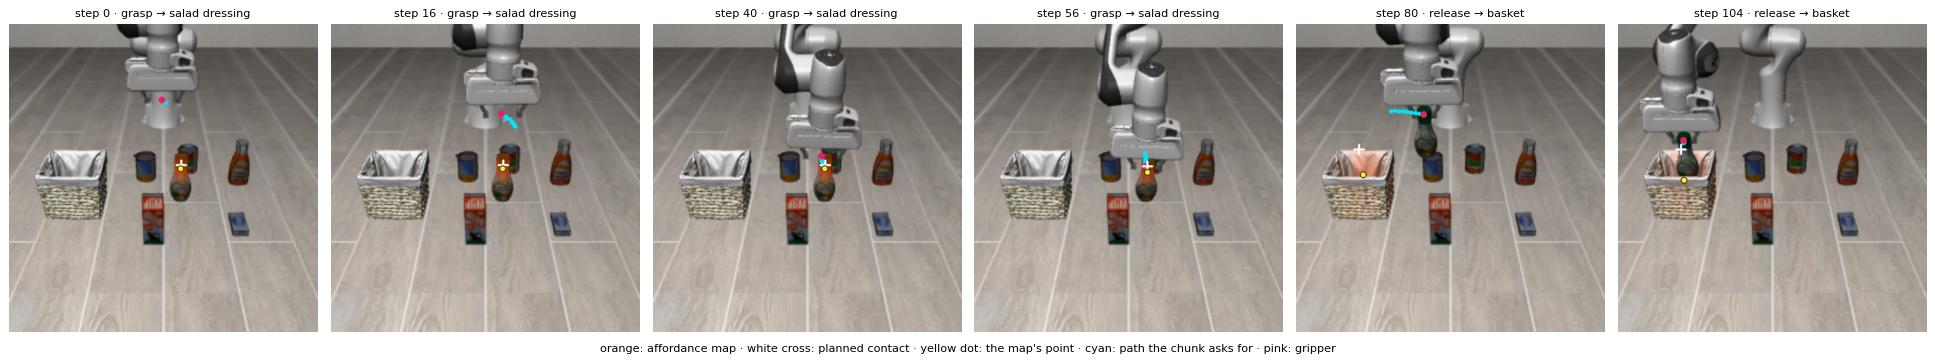

instruction: “pick up the salad dressing and place it in the basket”; shifts: {'salad_dressing_1': [-0.08, 0.05]}; the salad dressing ended in the basket


,queries,"horizontal gap, median (cm)","horizontal gap, range (cm)","contact above the map's point, median (cm)"
grasp,8,1.2,1.2–1.8,0.6
release,6,0.4,0.2–1.9,8.4


In [13]:
other = load_rollout_log(ROLLOUTS / "shift_9cm_ep1.npz")
other_plans = A.load_plans(other)
other_views = [A.view_at(other, other_plans, int(step), CONTAINER) for step in other.chunk_steps]
fig = A.film_strip(other, [other_views[k] for k in np.unique(np.linspace(0, len(other_views) - 1, 6).astype(int))], SCALE)
plt.show()
print(f"instruction: “{other.meta['instruction']}”; shifts: {other.meta['shifts']}; "
      f"the {H.pretty(other.target)} {'ended in the basket' if other.delivered else 'did not end in the basket'}")
display(A.gap_table(other_views))

**All 13 rollouts logged with depth** (same policy: 5 standard starts, 3 with the target moved, 5 that name another object). The gap columns are medians over the queries of a rollout, in cm: how far the planned contact lies from the map's point, both ORACLE.

In [14]:
display(A.gap_overview(ROLLOUTS, CONTAINER))

,asked for,outcome,grasp: horizontal,grasp: contact above,release: horizontal,release: contact above
ask_alphabet_soup_ep1,alphabet soup,no grasp,2.1,-0.1,NaN,NaN
ask_cream_cheese_ep1,cream cheese,no grasp,1.9,-0.9,NaN,NaN
ask_ketchup_ep1,ketchup,delivered,0.9,0.7,0.4,8.4
ask_milk_ep1,milk,not delivered,1.9,-0.4,4.5,9.3
ask_tomato_sauce_ep1,tomato sauce,delivered,1.6,-0.5,0.4,8.5
shift_16cm_ep1,salad dressing,not delivered,1.2,0.6,0.3,8.4
shift_4cm_ep1,salad dressing,delivered,1.2,0.6,0.4,8.4
shift_9cm_ep1,salad dressing,delivered,1.2,0.6,0.4,8.4
standard_ep0,salad dressing,delivered,1.2,0.5,0.3,8.4
standard_ep1,salad dressing,delivered,1.2,0.5,0.4,8.4


## What to take from this

**What the walk-through shows**
- **Where the affordance map sits.** It is an image-sized output between the VLM and the plan. It says where on the object, or where in the basket, the gripper should act. It reaches the robot only through the contact point of the plan.
- **A map gives a point on a surface; the plan needs the centre of the gripper.** For grasps the two are 0.9–2.1 cm apart horizontally and within 1 cm in height (13 rollouts). For releases the map's point lies on the basket and the release point 8.4–9.3 cm above it. Something has to add that offset: a plan head that predicts it, or an action head trained on map points directly.
- **The plan changes inside an episode.** Once the object is in the gripper the plan switches from the grasp to the release, and the map moves from the object to the basket. Something has to decide that switch. Here the simulator's contact flags do.
- **What the action head adds.** Everything between the gripper and the contact: the path of the chunk, the descent, the moment the gripper closes. The controller only follows each small step; in the chunk shown the gripper moved 6.9 cm where the chunk asked for 7.9 cm.
- **How coarse the VLM's own tokens are.** Each image becomes 8 × 8 tokens, so one token covers 32 × 32 pixels. The tomato sauce is 18 × 25 pixels: smaller than one token. A map that marks part of such an object needs a head that works at a finer resolution than the tokens.

**What is not real here**
- **The map, the contact, the approach direction, the switch and the episode state are ORACLE.** The rollout was driven by the ORACLE contact. Driving it with the map's point (1–2 cm off for grasps) has not been run.
- **The definition of the map is my choice for this picture.** A Gaussian, 3 cm wide, around the place where the demonstrations hold the object. It is not a decision.
- **The size is small.** One policy and 13 rollouts logged with depth, of which 9 delivered the named object; two are shown in detail.

**Questions this raises**
1. **What should the map mark?** The part of the object the fingers hold (as here), the whole target object, or what your earlier affordance work produces?
2. **Where does the 3D contact come from?** The map's point plus a predicted offset, or a contact regressed directly with the map as a side output?
3. **Who decides between grasp and release,** and when the plan switches?
4. **Is 8 × 8 tokens per image enough** to place a map on small objects, or does the affordance head need finer image features?